# 18. Pengujian ketahanan (robustness)
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** menguji model yang dilatih pada citra asli terhadap Gaussian noise (sigma=15, skala 0-255), Low Light (kecerahan x0,5), blur Gaussian 15x15, dan rotasi 10 derajat (berlawanan arah jarum jam, tepi diisi hitam). Gangguan hanya diterapkan pada citra uji. Pooled dan ketiga situs dievaluasi pada skema yang sama (80:20 dan 80:10:10). `BERSIHKAN = True` membuang citra identik, pasangan berlabel bertentangan, dan (bila `BUANG_VARIAN = True`) citra varian FV/RA.

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `hasil_robustness_konsisten.csv`.

**Kaitan dengan naskah:** Bagian 3.9, Tabel 12.

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

In [1]:
!pip install lightgbm -q

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [3]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def bersihkan(df):
    """Buang salinan identik (MD5; simpan satu) dan KEDUA file bila citra identik berlabel berbeda."""
    df = df.copy(); df['md5'] = df['path'].map(md5)
    konflik = df.groupby('md5').label.transform('nunique') > 1
    salinan = df.duplicated('md5', keep='first')
    out = df[~(konflik | salinan)].reset_index(drop=True)
    if BUANG_VARIAN:
        out = out.drop(index=sorted({a for a, b in pasangan_varian(out)})).reset_index(drop=True)
    return out

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [4]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [5]:
# ===== ROBUSTNESS: model dilatih pada citra asli, gangguan HANYA pada citra uji =====
# Parameter sama dengan laporan (skala piksel 0-255). Skema ditampilkan di setiap baris hasil.
NOISE_SIGMA, LOWLIGHT, BLUR_K, ROT_DEG = 15, 0.5, (15, 15), 10
rng = np.random.default_rng(SEED)

def p_noise(img):    return np.clip(img.astype(np.float32) + rng.normal(0, NOISE_SIGMA, img.shape), 0, 255).astype(np.uint8)
def p_lowlight(img): return np.clip(img.astype(np.float32) * LOWLIGHT, 0, 255).astype(np.uint8)
def p_blur(img):     return cv2.GaussianBlur(img, BLUR_K, 0)
def p_rotate(img):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ROT_DEG, 1.0)           # +10 derajat, berlawanan arah jarum jam
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))  # tepi diisi hitam
PERTURB = {'Original': lambda im: im, 'Gaussian Noise (sigma=15)': p_noise, 'Low Light (x0,5)': p_lowlight,
           'Blur (15x15)': p_blur, 'Rotasi (10 derajat)': p_rotate}

BERSIHKAN = True   # True: buang citra identik (MD5) dan pasangan berlabel bertentangan; False: tanpa pembersihan
df = list_used_files()
if BERSIHKAN: df = bersihkan(df)
df = df.reset_index(drop=True)
if 'md5' not in df.columns: df['md5'] = df.path.map(md5)
print('Jumlah citra dipakai:', len(df), df.groupby('site').size().to_dict())
feat_orig = np.array([feat_original(cv2.imread(p))[0] for p in df.path])

def X_of(F, d, with_site):
    return np.column_stack([F, d.site_id.to_numpy(float)]) if with_site else F

rows = []
for scheme in ['80:20', '80:10:10']:
    for scope in ['Pooled'] + list(SITES):
        d = df if scope == 'Pooled' else df[df.site == scope]
        gi = d.index.to_numpy(); y = d.label.to_numpy()
        tr, va, te = split_idx(y, scheme)
        bocor = cek_kebocoran(d.md5.to_numpy(), tr, va, te, wajib=BERSIHKAN)
        vlin = cek_varian(pasangan_varian(d.reset_index(drop=True)), tr, va, te)
        ws = scope == 'Pooled'
        Xtr = X_of(feat_orig[gi[tr]], d.iloc[tr], ws)
        sc, m = fit_lgbm(Xtr, y[tr])
        base = None
        for name, fn in PERTURB.items():
            Fte = np.array([feat_original(fn(cv2.imread(df.path[g])))[0] for g in gi[te]])
            pr, pb = predict_lgbm(sc, m, X_of(Fte, d.iloc[te], ws))
            r = metrics_from(y[te], pr, pb)
            if name == 'Original': base = r
            rows.append(dict(skema=scheme, model=scope, gangguan=name, identik_latih_uji=bocor['latih-uji'], varian_lintas_partisi=vlin, n_test=r['n_test'], TP=r['TP'], TN=r['TN'], FP=r['FP'], FN=r['FN'],
                             acc=r['acc'], auc=r['auc'], sens=r['sens'], spec=r['spec'],
                             dropoff_acc=base['acc'] - r['acc'], dropoff_auc=base['auc'] - r['auc']))
hasil = pd.DataFrame(rows).round(2)
hasil.to_csv(os.path.join(OUT, 'hasil_robustness_konsisten.csv'), index=False)
print(hasil.to_string(index=False))

Jumlah citra dipakai: 1345 {'Conjunctiva': 514, 'Nail': 312, 'Palm': 519}
   skema       model                  gangguan  identik_latih_uji  varian_lintas_partisi  n_test  TP  TN  FP  FN   acc   auc   sens  spec  dropoff_acc  dropoff_auc
   80:20      Pooled                  Original                  0                      0     269 144  49  43  33 71.75 76.93  81.36 53.26         0.00         0.00
   80:20      Pooled Gaussian Noise (sigma=15)                  0                      0     269 144  28  64  33 63.94 68.72  81.36 30.43         7.81         8.21
   80:20      Pooled          Low Light (x0,5)                  0                      0     269 166   9  83  11 65.06 63.32  93.79  9.78         6.69        13.61
   80:20      Pooled              Blur (15x15)                  0                      0     269 146  33  59  31 66.54 72.59  82.49 35.87         5.20         4.34
   80:20      Pooled       Rotasi (10 derajat)                  0                      0     269 144  46  

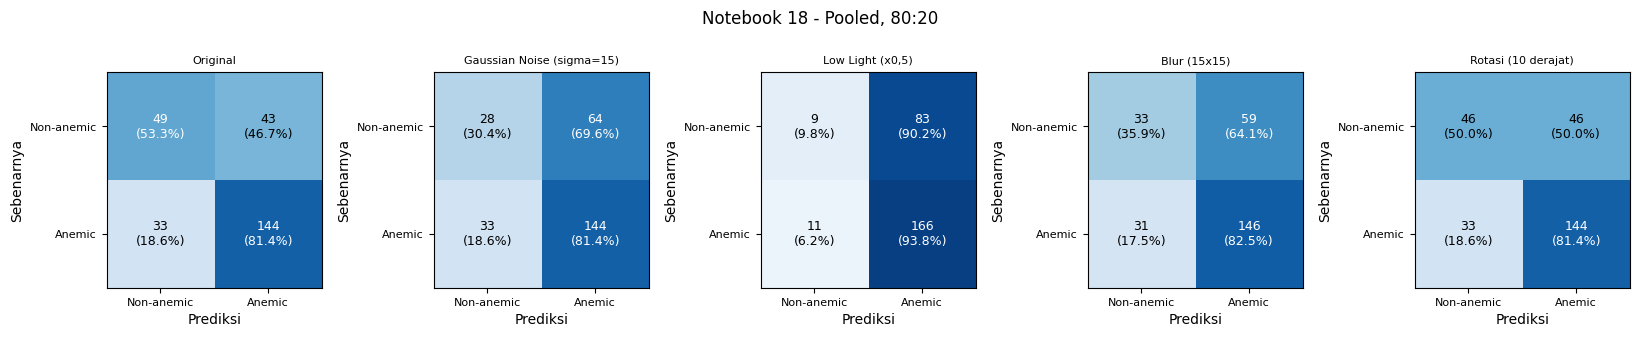

In [8]:
r_ = pd.read_csv(f'{OUT}/hasil_robustness_konsisten.csv')
d = r_[(r_.skema == '80:20') & (r_.model == 'Pooled')]                         # model: 'Palm', 'Nail', 'Conjunctiva'
grid_cm(d, lambda r: r['gangguan'], ncol=5, simpan='cm_nb18_pooled_80_20.png', judul_utama='Notebook 18 - Pooled, 80:20')

In [7]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()